# MERA benchmark: Stages 1-4

Critical transverse-field Ising chain, `H = -J sum Z_i Z_{i+1} - h sum X_i`, `J = h = 1`, periodic, `L = 2^n` sites. Binary MERA on CPU (NumPy + `opt_einsum`).

- **Stage 1:** exact reference energy (free fermions), validated against exact diagonalization.
- **Stage 2:** finite binary MERA and its energy by Hamiltonian coarse-graining, validated against a brute-force state vector.
- **Stage 3:** Evenbly-Vidal optimizer. Environments come from the same network as the energy (manual back-propagation through the coarse-graining), validated against finite differences, then used for SVD updates.

Install if needed: `pip install numpy scipy opt_einsum matplotlib`.

In [1]:
import itertools, time
import numpy as np
import opt_einsum as oe
import scipy.sparse as sp
import scipy.sparse.linalg as sla
from scipy.linalg import eigh

np.set_printoptions(precision=6, suppress=True)

## Stage 1: exact reference

Periodic chain, even-parity sector, antiperiodic momenta `k = pi(2m+1)/L`: `E0 = -sum_k sqrt(J^2 + h^2 - 2 J h cos k)`. At criticality `E0/L -> -4/pi`.

In [2]:
def exact_energy_ising(L, J=1.0, h=1.0):
    k = np.pi * (2 * np.arange(L) + 1) / L
    return -np.sum(np.sqrt(J**2 + h**2 - 2 * J * h * np.cos(k)))


def ed_energy_ising(L, J=1.0, h=1.0):
    """Brute-force sparse ED, used only to validate the formula at small L."""
    X = sp.csr_matrix([[0, 1], [1, 0]], dtype=float)
    Z = sp.csr_matrix([[1, 0], [0, -1]], dtype=float)
    I = sp.identity(2, format="csr")

    def op(o, i):
        out = None
        for s in range(L):
            m = o if s == i else I
            out = m if out is None else sp.kron(out, m, format="csr")
        return out

    H = sp.csr_matrix((2**L, 2**L))
    for i in range(L):
        H = H - J * (op(Z, i) @ op(Z, (i + 1) % L)) - h * op(X, i)
    return sla.eigsh(H, k=1, which="SA")[0][0]


print(f"{'L':>4} {'exact formula':>16} {'ED':>16} {'abs diff':>10}")
for L in (4, 6, 8, 10, 12):
    ex, ed = exact_energy_ising(L), ed_energy_ising(L)
    print(f"{L:>4} {ex:>16.10f} {ed:>16.10f} {abs(ex-ed):>10.1e}")
    assert abs(ex - ed) < 1e-8
for L in (16, 64, 1024):
    print(f"L={L:>5}  E0/L = {exact_energy_ising(L)/L:.8f}   (-4/pi = {-4/np.pi:.8f})")

   L    exact formula               ED   abs diff
   4    -5.2262518595    -5.2262518595    2.7e-15
   6    -7.7274066103    -7.7274066103    2.7e-15
   8   -10.2516617910   -10.2516617910    2.0e-14
  10   -12.7849064430   -12.7849064430    7.1e-15
  12   -15.3225951511   -15.3225951511    3.6e-15
L=   16  E0/L = -1.27528715   (-4/pi = -1.27323954)
L=   64  E0/L = -1.27336739   (-4/pi = -1.27323954)
L= 1024  E0/L = -1.27324004   (-4/pi = -1.27323954)


## Stage 2: binary MERA

One layer on a ring of `N` sites: isometries `w_j` on sites `(2j, 2j+1)` (two sites -> one site of dimension `min(chi, D^2)`), disentanglers `u_j` on sites `(2j+1, 2j+2 mod N)`. Layers repeat `L -> L/2 -> ... -> 2`; the top is a state on 2 sites.

Conventions (real tensors): `U[a,b,c,d]` orthogonal as a matrix `(ab) x (cd)`; `W[x,p,q]` with orthonormal rows. Operators ascend as `O' = W (U O U^T) W^T`; states descend as `U^T W^T |coarse>`.

The ascend routine builds the `einsum` for an operator on *any* set of sites, inserting identities automatically where a tensor only partly overlaps it. Contraction paths are found once (`opt_einsum`) and cached.

In [3]:
def random_orthogonal(n, rng):
    q, r = np.linalg.qr(rng.normal(size=(n, n)))
    return q * np.sign(np.diag(r))

def random_isometry(d_in, d_out, rng):
    q, _ = np.linalg.qr(rng.normal(size=(d_in, d_out)))
    return q.T

class MERA:
    def __init__(self, L, chi, d=2, seed=0):
        assert L >= 4 and (L & (L - 1)) == 0
        rng = np.random.default_rng(seed)
        self.L, self.chi, self.d = L, chi, d
        self.n_layers = int(np.log2(L)) - 1
        self.dims = [d]
        self.U, self.W = [], []
        N, D = L, d
        for _ in range(self.n_layers):
            D_out = min(chi, D * D)
            self.U.append([random_orthogonal(D * D, rng).reshape(D, D, D, D) for _ in range(N // 2)])
            self.W.append([random_isometry(D * D, D_out, rng).reshape(D_out, D, D) for _ in range(N // 2)])
            N //= 2; D = D_out; self.dims.append(D)


m = MERA(16, chi=4)
print("dims per layer:", m.dims, "| layers:", m.n_layers)

dims per layer: [2, 4, 4, 4] | layers: 3


In [4]:
_SPEC_CACHE = {}
_PATH_CACHE = {}

def ascend_spec(op_sites, N):
    key = (tuple(op_sites), N)
    if key not in _SPEC_CACHE:
        _SPEC_CACHE[key] = _ascend_spec(op_sites, N)
    return _SPEC_CACHE[key]

def _ascend_spec(op_sites, N):
    cnt = itertools.count()
    new = lambda: next(cnt)
    sites = list(op_sites)
    R = {s: new() for s in sites}
    C = {s: new() for s in sites}
    op_labels = [R[s] for s in sites] + [C[s] for s in sites]
    spec = []
    support = set(sites)
    for j in range(N // 2):
        pair = ((2 * j + 1) % N, (2 * j + 2) % N)
        if not (set(pair) & support):
            continue
        up_r, up_c, low_r, low_c = [], [], [], []
        for s in pair:
            up_r.append(new()); up_c.append(new())
            if s in support:
                low_r.append(R[s]); low_c.append(C[s])
            else:
                z = new(); low_r.append(z); low_c.append(z)
        spec.append(("U", j, "ket", up_r + low_r))
        spec.append(("U", j, "bra", up_c + low_c))
        for s, ur, uc in zip(pair, up_r, up_c):
            R[s], C[s] = ur, uc
            support.add(s)
    coarse = {}
    for j in range(N // 2):
        pair = (2 * j, 2 * j + 1)
        if not (set(pair) & support):
            continue
        xr, xc = new(), new()
        low_r, low_c = [], []
        for s in pair:
            if s in support:
                low_r.append(R[s]); low_c.append(C[s])
            else:
                z = new(); low_r.append(z); low_c.append(z)
        spec.append(("W", j, "ket", [xr] + low_r))
        spec.append(("W", j, "bra", [xc] + low_c))
        coarse[j] = (xr, xc)
    cs = sorted(coarse)
    out = [coarse[j][0] for j in cs] + [coarse[j][1] for j in cs]
    return spec, op_labels, out, tuple(cs)

def contract_spec(spec, op_labels, op_tensor, Ul, Wl, out, skip=None, extra=None):
    args = []
    if skip != "op":
        args += [op_tensor, op_labels]
    for idx, (kind, j, role, labels) in enumerate(spec):
        if idx == skip:
            continue
        args += [Ul[j] if kind == "U" else Wl[j], labels]
    if extra is not None:
        args += extra
    shapes = tuple(a.shape for a in args[::2])
    key = (tuple(tuple(l) for l in args[1::2]), tuple(out), shapes)
    if key not in _PATH_CACHE:
        _PATH_CACHE[key] = oe.contract_path(*args, out, optimize="auto-hq")[0]
    return oe.contract(*args, out, optimize=_PATH_CACHE[key])

In [5]:
def ising_bond_terms(L, J=1.0, h=1.0):
    X = np.array([[0.0, 1.0], [1.0, 0.0]]); Z = np.diag([1.0, -1.0]); I = np.eye(2)
    hb = (-J * np.kron(Z, Z) - 0.5 * h * (np.kron(X, I) + np.kron(I, X))).reshape(2, 2, 2, 2)
    terms = []
    for i in range(L):
        j = (i + 1) % L
        if i < j: terms.append(((i, j), hb))
        else: terms.append(((j, i), hb.transpose(1, 0, 3, 2)))
    return terms

def top_hamiltonian(ops, D):
    Htop = np.zeros((D * D, D * D))
    for sites, t in ops.items():
        mat = t.reshape(D ** len(sites), D ** len(sites))
        if sites == (0, 1): Htop += mat
        elif sites == (0,): Htop += np.kron(mat, np.eye(D))
        elif sites == (1,): Htop += np.kron(np.eye(D), mat)
        else: raise ValueError(sites)
    return Htop

def mera_energy(mera, terms):
    ops = {}
    for s, t in terms: ops[s] = ops[s] + t if s in ops else t
    N = mera.L
    for k in range(mera.n_layers):
        nxt = {}
        for sites, t in ops.items():
            spec, opl, out, cs = ascend_spec(sites, N)
            r = contract_spec(spec, opl, t, mera.U[k], mera.W[k], out)
            nxt[cs] = nxt[cs] + r if cs in nxt else r
        ops, N = nxt, N // 2
    D = mera.dims[-1]
    ev, evec = eigh(top_hamiltonian(ops, D))
    return ev[0], evec[:, 0]

### Check: coarse-grained energy vs full state vector

The same MERA is rebuilt as a `2^L` state vector (top state, then `W^T`, then `U^T` layer by layer) and `<H>` evaluated directly. Random tensors must agree to machine precision.

In [6]:
def mera_state(mera, top_vec):
    D = mera.dims[-1]
    psi = top_vec.reshape(D, D)
    N = 2
    for k in reversed(range(mera.n_layers)):
        for j in range(N):
            psi = np.tensordot(psi, mera.W[k][j], axes=([2 * j], [0]))
            psi = np.moveaxis(psi, [-2, -1], [2 * j, 2 * j + 1])
        N *= 2
        for j in range(N // 2):
            s1, s2 = (2 * j + 1) % N, (2 * j + 2) % N
            psi = np.tensordot(psi, mera.U[k][j], axes=([s1, s2], [0, 1]))
            psi = np.moveaxis(psi, [-2, -1], [s1, s2])
    return psi


def state_energy(psi, J=1.0, h=1.0):
    L = psi.ndim
    norm = np.sum(psi**2)
    z = np.array([1.0, -1.0])
    p = psi**2
    E = 0.0
    for i in range(L):
        j = (i + 1) % L
        si = [1] * L; si[i] = 2
        sj = [1] * L; sj[j] = 2
        E += -J * np.sum(p * z.reshape(si) * z.reshape(sj)) - h * np.sum(psi * np.flip(psi, axis=i))
    return E / norm, norm


worst = 0.0
for L in (4, 8, 16):
    for chi in (2, 3, 4, 6):
        for seed in (0, 1):
            m = MERA(L, chi, seed=seed)
            E_cg, top = mera_energy(m, ising_bond_terms(L))
            E_sv, norm = state_energy(mera_state(m, top))
            worst = max(worst, abs(E_cg - E_sv))
print("worst |E_coarse_grained - E_state_vector| =", worst)
assert worst < 1e-10
print("PASS")

worst |E_coarse_grained - E_state_vector| = 1.1546319456101628e-14
PASS


## Stage 3: Evenbly-Vidal optimizer

The energy is `E = sum_S Tr(rho_S H_S)`: Hamiltonian terms ascend through the layers, and the top state gives density matrices `rho_S` that are then *descended*. Rather than hand-deriving descending superoperators, the backward pass reuses the ascend networks: the environment of a tensor is the contraction of its network with that tensor removed, closed with the density matrix of the layer above. For a real tensor `T` this gives `dE/dT = 2 Gamma`.

Update: with the environment `Gamma` fixed, the energy is linear in `T`, so the minimizer over orthogonal (or isometric) matrices is `T = -A B^T` where `Gamma = A S B^T` is the SVD. The top state is the lowest eigenvector of the top Hamiltonian at every step.

In [7]:
def energy_and_grads(mera, terms):
    K, L = mera.n_layers, mera.L
    ops = {}
    for s, t in terms: ops[s] = ops[s] + t if s in ops else t
    layers, N = [], L
    for k in range(K):
        calls, nxt = [], {}
        for sites, t in ops.items():
            spec, opl, out, cs = ascend_spec(sites, N)
            r = contract_spec(spec, opl, t, mera.U[k], mera.W[k], out)
            calls.append((sites, t, spec, opl, out, cs))
            nxt[cs] = nxt[cs] + r if cs in nxt else r
        layers.append(calls); ops, N = nxt, N // 2
    D = mera.dims[-1]
    ev, evec = eigh(top_hamiltonian(ops, D))
    E, t2 = ev[0], evec[:, 0].reshape(D, D)
    rho = {}
    for sites in ops:
        if sites == (0, 1): rho[sites] = np.einsum("ab,cd->abcd", t2, t2)
        elif sites == (0,): rho[sites] = t2 @ t2.T
        else: rho[sites] = t2.T @ t2
    gU = [[np.zeros_like(u) for u in mera.U[k]] for k in range(K)]
    gW = [[np.zeros_like(w) for w in mera.W[k]] for k in range(K)]
    for k in reversed(range(K)):
        rho_prev = {}
        for sites, t, spec, opl, out, cs in layers[k]:
            extra = [rho[cs], out]
            g_op = contract_spec(spec, opl, t, mera.U[k], mera.W[k], opl, skip="op", extra=extra)
            rho_prev[sites] = rho_prev[sites] + g_op if sites in rho_prev else g_op
            for idx, (kind, j, role, labels) in enumerate(spec):
                if role != "ket": continue
                g = contract_spec(spec, opl, t, mera.U[k], mera.W[k], labels, skip=idx, extra=extra)
                (gU if kind == "U" else gW)[k][j] += g
        rho = rho_prev
    return E, gU, gW

### Check: environments vs finite differences

`dE/dT` from the backward pass (`2 * Gamma`) must match a central finite difference of the energy on random tensor entries (energy re-diagonalized at the top each time).

In [8]:
L, chi = 8, 4
m = MERA(L, chi, seed=1)
terms = ising_bond_terms(L)
E, gU, gW = energy_and_grads(m, terms)
assert abs(E - mera_energy(m, terms)[0]) < 1e-12

rng = np.random.default_rng(5)
eps, worst = 1e-6, 0.0
print(f"{'tensor':>10} {'entry':>14} {'finite diff':>14} {'2*Gamma':>14}")
for kind, k, j in [("U", 0, 0), ("U", 0, 3), ("W", 0, 1), ("U", 1, 1), ("W", 1, 0), ("W", 1, 1)]:
    arr = (m.U if kind == "U" else m.W)[k][j]
    g = (gU if kind == "U" else gW)[k][j]
    for _ in range(3):
        idx = tuple(int(rng.integers(0, s)) for s in arr.shape)
        old = arr[idx]
        arr[idx] = old + eps; Ep, _ = mera_energy(m, terms)
        arr[idx] = old - eps; Em, _ = mera_energy(m, terms)
        arr[idx] = old
        fd = (Ep - Em) / (2 * eps)
        worst = max(worst, abs(fd - 2 * g[idx]))
        print(f"{kind + str((k, j)):>10} {str(idx):>14} {fd:>14.8f} {2 * g[idx]:>14.8f}")
print("\nworst |FD - 2*Gamma| =", worst)
assert worst < 1e-6
print("PASS")

    tensor          entry    finite diff        2*Gamma
   U(0, 0)   (1, 1, 0, 1)    -0.25585659    -0.25585659
   U(0, 0)   (0, 1, 1, 0)    -0.70546399    -0.70546399
   U(0, 0)   (1, 0, 0, 0)    -0.70274563    -0.70274563
   U(0, 3)   (1, 0, 0, 0)    -1.09163525    -1.09163525
   U(0, 3)   (0, 0, 0, 1)    -0.23608957    -0.23608957
   U(0, 3)   (0, 1, 1, 0)    -0.52817387    -0.52817387
   W(0, 1)      (1, 0, 0)    -1.76654104    -1.76654104
   W(0, 1)      (3, 0, 1)     0.22822593     0.22822593
   W(0, 1)      (3, 1, 0)     0.13015428     0.13015427
   U(1, 1)   (1, 2, 1, 2)     0.04226461     0.04226461


   U(1, 1)   (2, 2, 0, 3)    -0.20763987    -0.20763987
   U(1, 1)   (2, 3, 1, 1)    -0.05487651    -0.05487651
   W(1, 0)      (3, 0, 0)    -0.11619548    -0.11619548
   W(1, 0)      (1, 2, 0)     0.36756768     0.36756768
   W(1, 0)      (3, 1, 0)     0.34663672     0.34663672
   W(1, 1)      (2, 3, 3)     0.47531125     0.47531125
   W(1, 1)      (3, 1, 0)    -0.89239473    -0.89239473
   W(1, 1)      (3, 2, 3)     1.15217939     1.15217939

worst |FD - 2*Gamma| = 1.9551076868573602e-09
PASS


In [9]:
def polar_min(G2):
    A, S, Bt = np.linalg.svd(G2, full_matrices=False)
    return -A @ Bt


def optimize(mera, terms, n_iter=200, verbose=50, exact=None):
    """Layer-by-layer Evenbly-Vidal sweeps. One gradient pass per iteration; the tensors of one layer
    are updated by SVD polar steps. If the simultaneous update would raise the energy, only half of the
    tensors (even j, then odd j) are tried, so the energy never increases."""
    K, L = mera.n_layers, mera.L
    hist, t0 = [], time.perf_counter()
    for it in range(n_iter):
        E, gU, gW = energy_and_grads(mera, terms)
        hist.append(E)
        k = it % K
        D, Do = mera.dims[k], mera.dims[k + 1]
        n = len(mera.U[k])
        newU = [polar_min(gU[k][j].reshape(D * D, D * D)).reshape(D, D, D, D) for j in range(n)]
        newW = [polar_min(gW[k][j].reshape(Do, D * D)).reshape(Do, D, D) for j in range(n)]
        oldU, oldW = list(mera.U[k]), list(mera.W[k])
        for subset in (None, 0, 1):
            for j in range(n):
                if subset is None or j % 2 == subset:
                    mera.U[k][j], mera.W[k][j] = newU[j], newW[j]
            if mera_energy(mera, terms)[0] <= E + 1e-12:
                break
            mera.U[k], mera.W[k] = list(oldU), list(oldW)
        if verbose and (it % verbose == 0 or it == n_iter - 1):
            msg = f"it {it:>4}  E/L = {E / L:.8f}"
            if exact is not None:
                msg += f"  err/site = {(E - exact) / L:.2e}"
            print(msg + f"  [{time.perf_counter() - t0:.0f}s]")
    hist.append(mera_energy(mera, terms)[0])
    return np.array(hist)

### Run: L = 16

One iteration = one full gradient pass, then an update of the tensors of one layer (cycling through layers). The energy never increases. Change `RUNS` to try other sizes; time per iteration grows quickly with `chi` (about `chi^9`) and with `L` because this version does not yet tie tensors across sites.

--- chi = 2 ---


it    0  E/L = -0.06915834  err/site = 1.21e+00  [3s]


it   40  E/L = -1.21413336  err/site = 6.12e-02  [8s]


it   80  E/L = -1.26471576  err/site = 1.06e-02  [14s]


it  120  E/L = -1.26565348  err/site = 9.63e-03  [20s]


it  160  E/L = -1.26565767  err/site = 9.63e-03  [26s]


... (7 outputs left out)

it    0  E/L = -0.05470867  err/site = 1.22e+00  [2s]


it   40  E/L = -1.27259024  err/site = 2.70e-03  [36s]


it   80  E/L = -1.27309948  err/site = 2.19e-03  [71s]


it  119  E/L = -1.27366224  err/site = 1.62e-03  [104s]


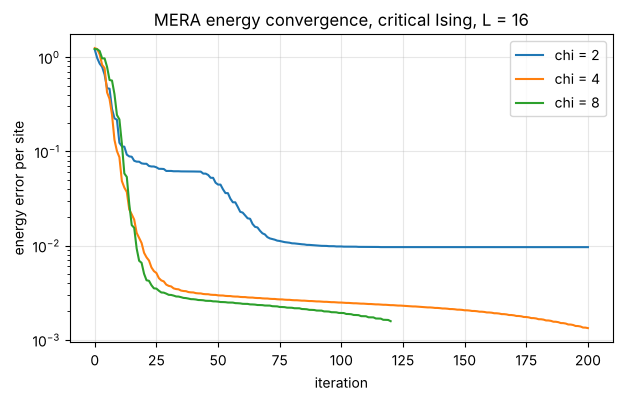

 chi  iters            E/L   err/site    rel err  time (s)
   2    200    -1.26565832   9.63e-03   7.55e-03        33
   4    200    -1.27395610   1.33e-03   1.04e-03        40
   8    120    -1.27371031   1.58e-03   1.24e-03       104
exact E/L = -1.27528715


In [10]:
import matplotlib.pyplot as plt

L = 16
RUNS = {2: 200, 4: 200, 8: 120}      # chi -> iterations
Ex = exact_energy_ising(L)
terms = ising_bond_terms(L)

results = {}
for chi, n_iter in RUNS.items():
    print(f"--- chi = {chi} ---")
    mera = MERA(L, chi, seed=0)
    t0 = time.perf_counter()
    hist = optimize(mera, terms, n_iter=n_iter, verbose=40, exact=Ex)
    results[chi] = dict(hist=hist, time=time.perf_counter() - t0, mera=mera)
    assert np.all(np.diff(hist) <= 1e-10) and hist[-1] > Ex - 1e-9   # monotone and variational

fig, ax = plt.subplots(figsize=(7, 4))
for chi, r in results.items():
    ax.semilogy((r["hist"] - Ex) / L, label=f"chi = {chi}")
ax.set_xlabel("iteration"); ax.set_ylabel("energy error per site")
ax.set_title(f"MERA energy convergence, critical Ising, L = {L}")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

print(f"{'chi':>4} {'iters':>6} {'E/L':>14} {'err/site':>10} {'rel err':>10} {'time (s)':>9}")
for chi, r in results.items():
    E = r["hist"][-1]
    print(f"{chi:>4} {len(r['hist'])-1:>6} {E/L:>14.8f} {(E-Ex)/L:>10.2e} {(E-Ex)/abs(Ex):>10.2e} {r['time']:>9.0f}")
print(f"exact E/L = {Ex/L:.8f}")

## Status

- Stages 1-2: validated (exact vs ED; coarse-grained vs state vector).
- Stage 3: environments validated by finite differences; the optimizer lowers the energy monotonically.
- Stage 4: translation-tied sweeps, tolerance stopping, reproducible CSV export, peak-memory timing, and a scaling-dimension diagnostic are implemented below.

The included Stage 4 run is deliberately a small CPU smoke benchmark. Increase `L_VALUES`, `CHI_VALUES`, and `max_sweeps` in the run cell for the final benchmark campaign.


## Stage 4: reproducible benchmark harness

For the larger-size benchmark, tensors are tied across all positions in a layer: one disentangler `u` and one isometry `w` are optimized per layer. This is the finite-size version of translation invariance and removes the linear-in-`L` parameter growth of Stage 3.

One **sweep** visits every layer once. At each layer, the environments of all translated copies are summed before the polar/SVD update. The update is accepted only if it lowers the variational energy. Optimization stops when the energy improvement per site remains below `tol` for `patience` consecutive sweeps.


In [ ]:
class TiedMERA(MERA):
    """Binary MERA with one u and one w shared by every position in each layer."""
    def __init__(self, L, chi, d=2, seed=0):
        super().__init__(L, chi, d=d, seed=seed)
        for k in range(self.n_layers):
            self.U[k] = [self.U[k][0].copy() for _ in self.U[k]]
            self.W[k] = [self.W[k][0].copy() for _ in self.W[k]]


def _set_tied_layer(mera, k, u, w):
    mera.U[k] = [u.copy() for _ in mera.U[k]]
    mera.W[k] = [w.copy() for _ in mera.W[k]]


def optimize_tied(mera, terms, max_sweeps=50, tol=1e-8, patience=3, verbose=1, exact=None):
    """Monotone layer sweeps for a TiedMERA; returns (energy history, converged)."""
    if not isinstance(mera, TiedMERA):
        raise TypeError("optimize_tied expects a TiedMERA")
    L, stable = mera.L, 0
    hist = [mera_energy(mera, terms)[0]]
    t0 = time.perf_counter()

    for sweep in range(1, max_sweeps + 1):
        for k in range(mera.n_layers):
            E, gU, gW = energy_and_grads(mera, terms)
            D, Do = mera.dims[k], mera.dims[k + 1]
            Gu = np.sum(gU[k], axis=0).reshape(D * D, D * D)
            Gw = np.sum(gW[k], axis=0).reshape(Do, D * D)
            old_u, old_w = mera.U[k][0].copy(), mera.W[k][0].copy()
            new_u = polar_min(Gu).reshape(D, D, D, D)
            new_w = polar_min(Gw).reshape(Do, D, D)

            # Simultaneous and coordinate alternatives; retain the best variational step.
            best_E, best_u, best_w = E, old_u, old_w
            for cand_u, cand_w in ((new_u, new_w), (new_u, old_w), (old_u, new_w)):
                _set_tied_layer(mera, k, cand_u, cand_w)
                cand_E = mera_energy(mera, terms)[0]
                if cand_E < best_E - 1e-13:
                    best_E, best_u, best_w = cand_E, cand_u.copy(), cand_w.copy()
            _set_tied_layer(mera, k, best_u, best_w)

        E_new = mera_energy(mera, terms)[0]
        hist.append(E_new)
        improvement = (hist[-2] - hist[-1]) / L
        stable = stable + 1 if improvement <= tol else 0
        if verbose and (sweep == 1 or sweep % verbose == 0 or stable >= patience):
            msg = f"sweep {sweep:>3}  E/L = {E_new/L:.10f}  dE/L = {improvement:.2e}"
            if exact is not None:
                msg += f"  err/site = {(E_new-exact)/L:.2e}"
            print(msg + f"  [{time.perf_counter()-t0:.1f}s]")
        if stable >= patience:
            return np.asarray(hist), True
    return np.asarray(hist), False


### Benchmark and CSV export

Each `(L, chi)` run starts from a deterministic seed. `energy_err` is the variational error **per site** relative to the exact finite-chain result. `mem_gb` is peak Python/NumPy allocation measured by `tracemalloc`; it is portable and excludes the already-loaded interpreter and libraries. The required shared columns are kept first, followed by `iterations`, `converged`, and `seed` for reproducibility.


In [ ]:
import csv
import gc
import platform
import tracemalloc
from pathlib import Path

CSV_COLUMNS = [
    "method", "model", "L", "chi", "energy_err", "time_s", "mem_gb", "device",
    "iterations", "converged", "seed",
]


def benchmark_one(L, chi, max_sweeps=50, tol=1e-8, patience=3, seed=0, verbose=0):
    gc.collect()
    tracemalloc.start()
    t0 = time.perf_counter()
    mera = TiedMERA(L, chi, seed=seed)
    exact = exact_energy_ising(L)
    hist, converged = optimize_tied(
        mera, ising_bond_terms(L), max_sweeps=max_sweeps, tol=tol,
        patience=patience, verbose=verbose, exact=exact,
    )
    elapsed = time.perf_counter() - t0
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    row = {
        "method": "binary_mera_tied",
        "model": "critical_tfim_periodic",
        "L": int(L),
        "chi": int(chi),
        "energy_err": float((hist[-1] - exact) / L),
        "time_s": float(elapsed),
        "mem_gb": float(peak / 1e9),
        "device": "CPU-" + (platform.processor() or platform.machine() or "unknown"),
        "iterations": int(len(hist) - 1),
        "converged": bool(converged),
        "seed": int(seed),
    }
    return row, hist, mera


def run_stage4_benchmarks(L_values, chi_values, csv_path="mera_stage4_benchmarks.csv", **kwargs):
    rows, runs = [], {}
    for L in L_values:
        for chi in chi_values:
            print(f"--- Stage 4: L={L}, chi={chi} ---")
            row, hist, mera = benchmark_one(L, chi, **kwargs)
            rows.append(row)
            runs[(L, chi)] = {"row": row, "hist": hist, "mera": mera}
            print(
                f"err/site={row['energy_err']:.3e}, sweeps={row['iterations']}, "
                f"time={row['time_s']:.2f}s, peak={row['mem_gb']:.3f} GB"
            )
    path = Path(csv_path)
    with path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=CSV_COLUMNS)
        writer.writeheader()
        writer.writerows(rows)
    print("wrote", path.resolve())
    return rows, runs


In [ ]:
# Fast, deterministic smoke benchmark. Expand these lists for the final campaign.
# Suggested full grid: L_VALUES = (8, 16, 32), CHI_VALUES = (2, 4, 8)
L_VALUES = (8,)
CHI_VALUES = (2,)

stage4_rows, stage4_runs = run_stage4_benchmarks(
    L_VALUES, CHI_VALUES,
    csv_path="mera_stage4_benchmarks.csv",
    max_sweeps=3, tol=1e-7, patience=2, seed=0, verbose=1,
)

print(f"{'L':>4} {'chi':>4} {'err/site':>12} {'time(s)':>10} {'mem(GB)':>10} {'sweeps':>8} {'conv':>6}")
for row in stage4_rows:
    print(
        f"{row['L']:>4} {row['chi']:>4} {row['energy_err']:>12.3e} "
        f"{row['time_s']:>10.2f} {row['mem_gb']:>10.3f} "
        f"{row['iterations']:>8} {str(row['converged']):>6}"
    )


### Scaling-dimension check

At a layer where the incoming and outgoing bond dimensions are both `chi`, the averaged one-site ascending channel is scale invariant. If its eigenvalues are `lambda_alpha`, the binary-MERA scaling dimensions are

`Delta_alpha = -log_2(abs(lambda_alpha))`.

The identity must have `lambda = 1` and `Delta = 0`. For the critical Ising CFT, the leading primary dimensions include `Delta_sigma = 1/8` and `Delta_epsilon = 1`. A small finite MERA is not expected to reproduce these accurately, so the code reports the nearest measured dimensions rather than asserting agreement; the identity-channel check is asserted numerically.


In [ ]:
def one_site_scaling_superoperator(mera, layer=None):
    """Dense averaged one-site ascending channel at a saturated (D -> D) layer."""
    candidates = [k for k in range(mera.n_layers) if mera.dims[k] == mera.dims[k + 1]]
    if layer is None:
        if not candidates:
            raise ValueError("No scale-invariant D -> D layer; increase L or lower chi")
        layer = candidates[0]
    D, Do = mera.dims[layer], mera.dims[layer + 1]
    if D != Do:
        raise ValueError("Scaling dimensions require an equal-dimension D -> D layer")
    N = mera.L // (2 ** layer)
    S = np.zeros((D * D, D * D))

    for col in range(D * D):
        op = np.zeros((D, D))
        op.flat[col] = 1.0
        asc = np.zeros((D, D))
        for s in range(N):
            spec, opl, out, cs = ascend_spec((s,), N)
            coarse_op = contract_spec(spec, opl, op, mera.U[layer], mera.W[layer], out)
            q = (s // 2) % (N // 2)
            if len(cs) == 1:
                reduced = coarse_op
            elif len(cs) == 2:
                keep = cs.index(q)
                if keep == 0:
                    reduced = np.trace(coarse_op, axis1=1, axis2=3) / D
                else:
                    reduced = np.trace(coarse_op, axis1=0, axis2=2) / D
            else:
                raise RuntimeError(f"Unexpected coarse support {cs}")
            asc += reduced
        S[:, col] = (asc / N).reshape(-1)
    return S, layer


def scaling_dimensions(mera, n_values=8, layer=None):
    S, layer = one_site_scaling_superoperator(mera, layer=layer)
    identity_residual = np.linalg.norm(S @ np.eye(mera.dims[layer]).reshape(-1) - np.eye(mera.dims[layer]).reshape(-1))
    vals = np.linalg.eigvals(S)
    order = np.argsort(-np.abs(vals))
    vals = vals[order]
    keep = np.abs(vals) > 1e-12
    vals = vals[keep][:n_values]
    dims = -np.log2(np.abs(vals))
    return vals, dims, identity_residual, layer


def report_scaling_dimensions(mera, n_values=8):
    vals, dims, residual, layer = scaling_dimensions(mera, n_values=n_values)
    print(f"scale-invariant layer = {layer}; identity residual = {residual:.3e}")
    print(f"{'alpha':>5} {'lambda':>20} {'Delta':>12}")
    for i, (lam, delta) in enumerate(zip(vals, dims)):
        print(f"{i:>5} {lam:>20.12g} {delta:>12.6f}")
    assert residual < 1e-10
    for name, target in (("identity", 0.0), ("sigma", 1/8), ("epsilon", 1.0)):
        nearest = dims[np.argmin(np.abs(dims - target))]
        print(f"nearest to Ising {name:>8} (Delta={target:g}): {nearest:.6f}")
    return vals, dims


# Reuse the optimized smoke-run MERA; no second optimization is needed.
scaling_key = next(iter(stage4_runs))
scaling_eigenvalues, measured_dimensions = report_scaling_dimensions(
    stage4_runs[scaling_key]["mera"]
)
